# Industrial Machine Condition Classification (Three Classes)

**Aradhya Chakrabarti (MT2026012)**

This notebook contains code for:

- Loading the data
- Exploratory Data Analysis
- Data Cleaning
- Feature Engineering
- Data Preprocessing
- Model Evaluation
- Model Family Direct Comparisons (Baseline)
- Hyper-parameter Tuning for each model
- Experiment: Class Imbalance Handling
- Model Diagnostics
- Cross-Validation of shortlisted models
- Metrics Comparison
- Submission CSV Creation

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.pipeline import Pipeline as ImbalancedPipeline
except ImportError:  # not always preinstalled on Kaggle
    import subprocess
    import sys

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"], check=True)
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.pipeline import Pipeline as ImbalancedPipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme()
pd.set_option("display.max_columns", None)

KAGGLE_ROOT = Path("/kaggle/input")
KAGGLE_CANDIDATES = [
    KAGGLE_ROOT / "industrial-machine-condition-classification-mtech",
    KAGGLE_ROOT / "competitions" / "industrial-machine-condition-classification-mtech",
]
if KAGGLE_ROOT.exists():
    KAGGLE_CANDIDATES += [path.parent for path in KAGGLE_ROOT.rglob("student_dataset.csv")]

DATA = None
for candidate in KAGGLE_CANDIDATES:
    if (candidate / "student_dataset.csv").exists():
        DATA = candidate
        break

if DATA is not None:
    BASE = Path("/kaggle/working")
else:
    BASE = None
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "MT2026012" / "data" / "machine_condition").exists():
            BASE = folder / "MT2026012"
            break
        if (folder / "data" / "machine_condition").exists():
            BASE = folder
            break
    if BASE is None:
        raise FileNotFoundError(
            "Could not find the competition files. Run from the repository folder."
        )
    DATA = BASE / "data" / "machine_condition"

FIGURES = BASE / "figures"
SUBMISSIONS = BASE / "submissions" / "machine_condition"
RESULTS = BASE / "results"
for folder in (FIGURES, SUBMISSIONS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

if not (DATA / "student_dataset.csv").exists():
    raise FileNotFoundError(
        f"Could not find the competition files in {DATA}. "
        "On Kaggle, attach the competition data with Add Input."
    )
print("using data folder:", DATA)

# For reproducibility
SEED = 42
CLASS_NAMES = ["normal", "thermal", "mechanical"]

def set_seed(seed=SEED):
    """Initialise the random number generators."""
    import os
    import random
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)

set_seed()
print("working folder:", BASE)

def show_table(frame):
    """Print a table as plain text so it renders the same in every viewer."""
    print(frame.to_string())


using data folder: C:\Users\Aradhya\Desktop\ml_project\nb\MT2026012\data\machine_condition
working folder: C:\Users\Aradhya\Desktop\ml_project\nb\MT2026012


## 1. Data Loading

We are provided with:

- `student_dataset.csv`: 16,000 machines with the target column `condition` (0 = normal, 1 = thermal failure, 2 = mechanical failure),
- `test.csv`: 4,000 machines without the target,
- `sample_submission.csv`: sample output format (`unit_id`, `condition`).

In [2]:
train = pd.read_csv(DATA / "student_dataset.csv")
test = pd.read_csv(DATA / "test.csv")
template = pd.read_csv(DATA / "sample_submission.csv")

print("train:", train.shape, "| test:", test.shape, "| template:", template.shape)
show_table(train.head())

train: (16000, 13) | test: (4000, 12) | template: (4000, 2)
      unit_id unit_type  ambient_temp  process_temp  coolant_flow  shaft_speed  drive_torque  power_load  component_wear  thermal_stress  mechanical_load  vibration_index  condition
0  UNT-184174         M          21.5          56.4         17.85       1454.0          58.2       9.099            30.0           29.31            57.19            1.768          0
1  UNT-236234         H          29.9          65.0         30.88       1720.0          54.6      10.101            13.0           23.93            36.94            1.081          0
2  UNT-247460         M          26.4          47.8         19.75       1552.0          38.4       6.328            89.0           13.52            38.22            1.031          0
3  UNT-176316         M          28.8          60.9         19.10       1513.0          49.1       7.768            59.0           24.62            46.17            1.011          0
4  UNT-105110         S       

A short description of the columns:

```text
Column             Meaning
-----------------  ------------------------------------------------------------
unit_id            machine identifier, used only to line up the submission
unit_type          machine type, S / M / H
ambient_temp       ambient temperature
process_temp       process temperature
coolant_flow       coolant flow measurement
shaft_speed        shaft rotation speed
drive_torque       drive torque
power_load         estimated power load
component_wear     component wear measurement
thermal_stress     thermal stress indicator
mechanical_load    mechanical load indicator
vibration_index    vibration indicator
condition          target: 0 normal, 1 thermal failure, 2 mechanical failure
```

In [3]:
overview = pd.DataFrame(
    {
        "train": [
            train.shape[0],
            train.shape[1],
            int(train.duplicated().sum()),
            int(train.isna().sum().sum()),
        ],
        "test": [
            test.shape[0],
            test.shape[1],
            int(test.duplicated().sum()),
            int(test.isna().sum().sum()),
        ],
    },
    index=["rows", "columns", "duplicate rows", "missing cells"],
)
show_table(overview)

                train  test
rows            16000  4000
columns            13    12
duplicate rows      0     0
missing cells     493   123


There are no duplicate rows, but both files contain a small number of missing sensor readings. The missing entries are few in every column.

## 2. Exploratory Data Analysis

### 2.1 Class Distribution

The target has three classes. Before any modelling, we check how balanced they are, because an uneven split can make cause the accuracy to be higher than what the model is actually capable of.

            count  share (%)
normal       8000       50.0
thermal      4000       25.0
mechanical   4000       25.0
majority-to-minority ratio: 2.0


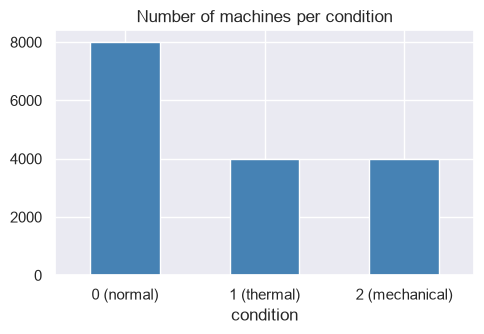

In [4]:
counts = train["condition"].value_counts().sort_index()
summary = pd.DataFrame({"count": counts, "share (%)": (counts / len(train) * 100).round(2)})
summary.index = [CLASS_NAMES[index] for index in summary.index]
show_table(summary)
print("majority-to-minority ratio:", round(float(counts.max() / counts.min()), 2))

fig, axis = plt.subplots(figsize=(5, 3.5))
counts.plot.bar(ax=axis, color="steelblue")
axis.set_title("Number of machines per condition")
axis.set_xlabel("condition")
axis.set_xticklabels(["0 (normal)", "1 (thermal)", "2 (mechanical)"], rotation=0)
fig.tight_layout()
plt.show()

The classes are 8,000 / 4,000 / 4,000, a 2:1:1 split. A model that always predicts "normal" would already score 50% accuracy, so accuracy alone is not enough to judge the models.

### 2.2 Sensor Analysis by Class

The sensors are supposed to reflect the physics of the failures, that is, thermal problems should show up in temperature and stress variables, mechanical problems in wear, load and vibration.

We check the average values per class below to see if that information can be observed in the data.

                  normal  thermal  mechanical
ambient_temp       25.23    28.10       25.37
process_temp       54.67    72.44       62.17
coolant_flow       17.49    19.15       17.38
shaft_speed      1399.35  1697.91     1580.93
drive_torque       49.13    63.93       57.94
power_load          7.30    11.60        9.65
component_wear     87.41    93.52      164.99
thermal_stress     21.32    37.85       30.23
mechanical_load    64.76    72.40       88.00
vibration_index     1.51     1.64        2.10


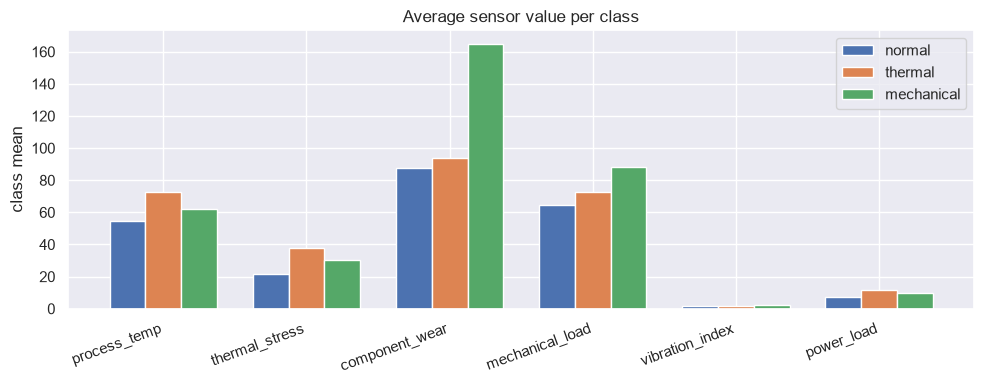

In [5]:
sensors = [
    "ambient_temp", "process_temp", "coolant_flow", "shaft_speed",
    "drive_torque", "power_load", "component_wear", "thermal_stress",
    "mechanical_load", "vibration_index",
]

group_means = train.groupby("condition")[sensors].mean().round(2).T
group_means.columns = CLASS_NAMES
show_table(group_means)

key_sensors = ["process_temp", "thermal_stress", "component_wear",
               "mechanical_load", "vibration_index", "power_load"]
fig, axis = plt.subplots(figsize=(10, 4))
positions = np.arange(len(key_sensors))
for offset, class_id in enumerate([0, 1, 2]):
    axis.bar(positions + (offset - 1) * 0.25, group_means.loc[key_sensors].iloc[:, class_id],
             0.25, label=CLASS_NAMES[class_id])
axis.set_xticks(positions)
axis.set_xticklabels(key_sensors, rotation=20, ha="right")
axis.set_title("Average sensor value per class")
axis.set_ylabel("class mean")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURES / "machine_sensor_means.png", dpi=150)
plt.show()

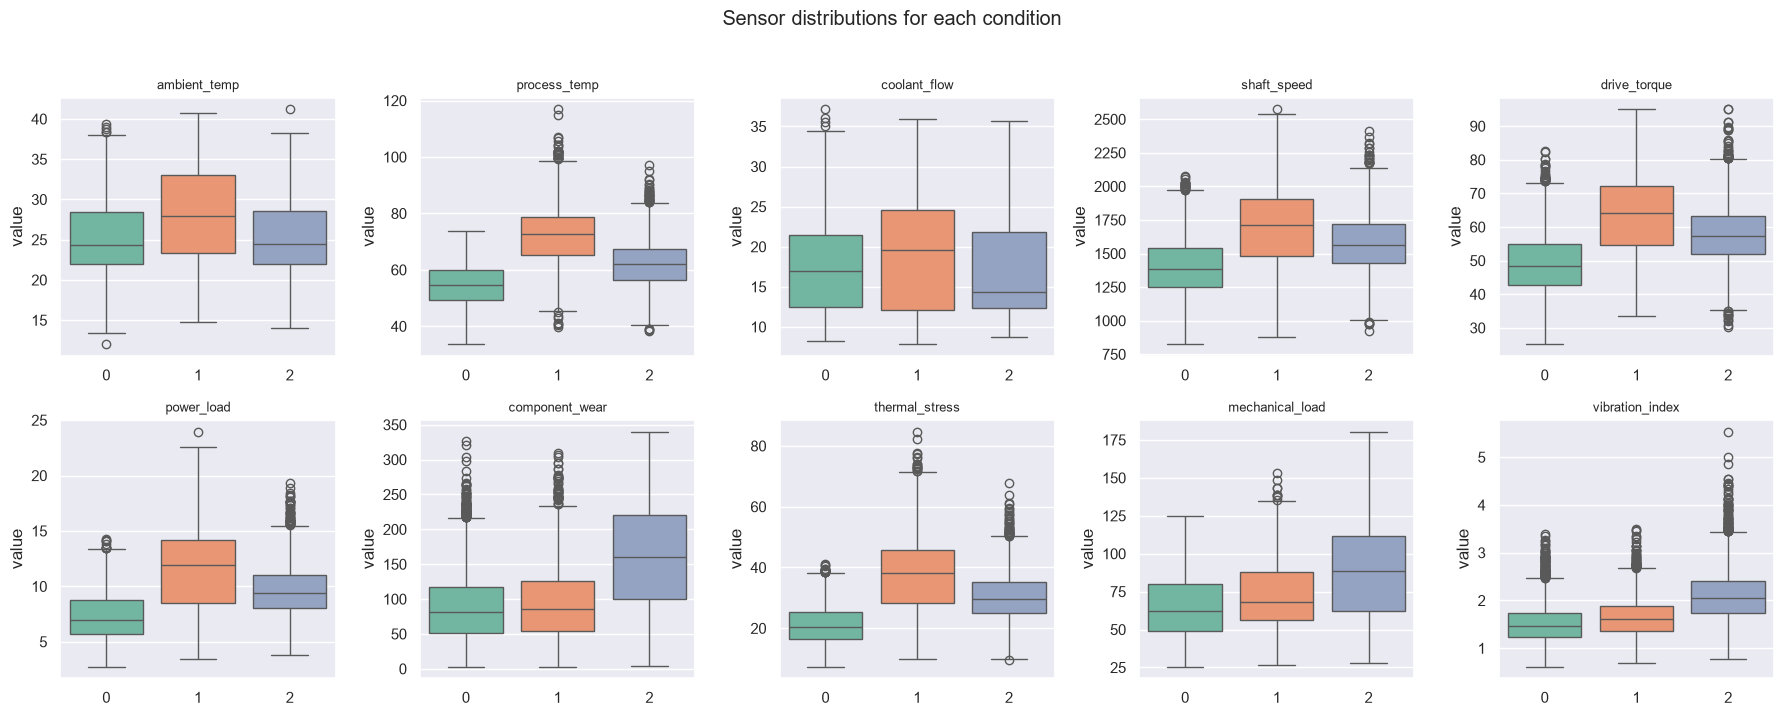

In [6]:
melted = train.melt(id_vars="condition", value_vars=sensors, var_name="sensor", value_name="value")
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for axis, sensor in zip(axes.ravel(), sensors):
    sns.boxplot(data=melted[melted["sensor"] == sensor], x="condition", y="value",
                hue="condition", legend=False, ax=axis, palette="Set2")
    axis.set_title(sensor, fontsize=9)
    axis.set_xlabel("")
fig.suptitle("Sensor distributions for each condition", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "machine_boxplots_by_class.png", dpi=150)
plt.show()

The averages and the boxes match the physics of the failures:

- **Thermal failures (class 1)** are hotter: mean `process_temp` 72.4 against 54.7 for normal and 62.2 for mechanical, and mean `thermal_stress` 37.9 against 21.3 for normal.
- **Mechanical failures (class 2)** show more wear and load: mean `component_wear` 165.0 against 87.4 for normal, `mechanical_load` 88.0 against 64.8, and `vibration_index` 2.10 against 1.51.
- Normal machines (class 0) have the lowest values of these variables, and the boxes for the two failure classes overlap the least exactly where the physical readings differ the most.

### 2.3 Missing Value Analysis

vibration_index    0.46
coolant_flow       0.38
component_wear     0.35
thermal_stress     0.31
ambient_temp       0.29
process_temp       0.28
mechanical_load    0.28
drive_torque       0.22
shaft_speed        0.20
power_load         0.16
unit_type          0.14


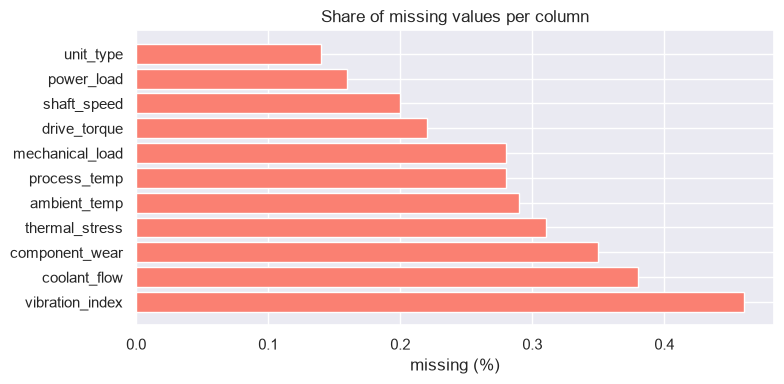

In [7]:
missing = (train[sensors + ["unit_type"]].isna().mean() * 100).round(2).sort_values(ascending=False)
print(missing[missing > 0].to_string())

fig, axis = plt.subplots(figsize=(8, 4))
axis.barh(missing.index, missing.values, color="salmon")
axis.set_xlabel("missing (%)")
axis.set_title("Share of missing values per column")
fig.tight_layout()
fig.savefig(FIGURES / "machine_missingness.png", dpi=150)
plt.show()

The column with the most number of missing values is `vibration_index`, which has 0.46% of its values missing (74 rows), and the others fall between 0.14% and 0.38%.

With numbers this small, filling the gaps with the column median is safe, and no rows need to be dropped.

`unit_type` has 22 missing entries (0.14%), which are filled with the most common type.

### 2.4 Correlation Analysis

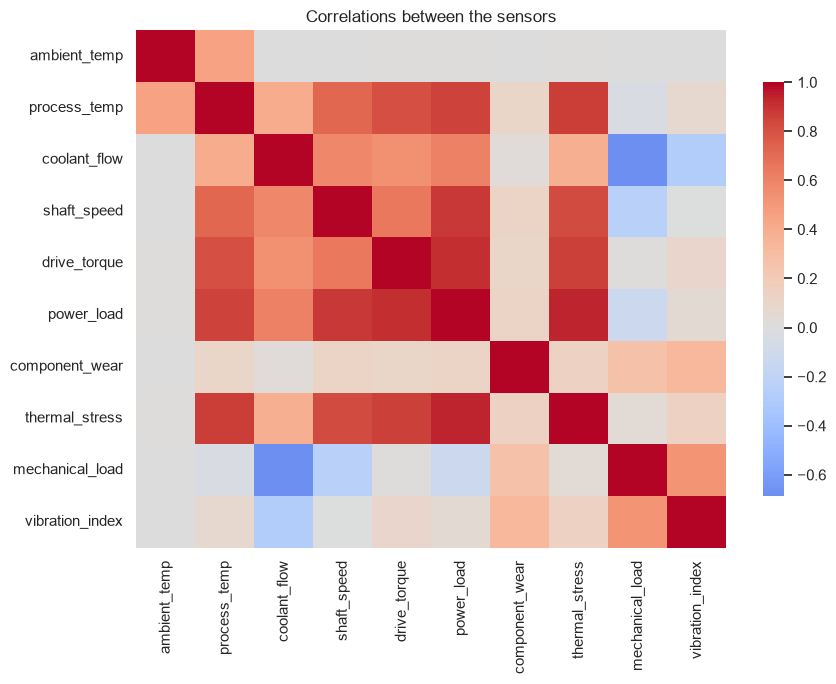

strongest pairs:
power_load    thermal_stress    0.93
drive_torque  power_load        0.92
shaft_speed   power_load        0.89
process_temp  thermal_stress    0.86
drive_torque  thermal_stress    0.86
process_temp  power_load        0.85


In [8]:
correlation = train[sensors].corr()
fig, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, cmap="coolwarm", center=0, ax=axis, cbar_kws={"shrink": 0.8})
axis.set_title("Correlations between the sensors")
fig.tight_layout()
fig.savefig(FIGURES / "machine_correlation.png", dpi=150)
plt.show()

strong = (
    correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    .stack().sort_values(key=abs, ascending=False).head(6)
)
print("strongest pairs:")
print(strong.round(2).to_string())

Fifteen pairs correlate above 0.5. The strongest are `power_load` with `thermal_stress` (0.93), `drive_torque` with `power_load` (0.92), and `process_temp` with `thermal_stress` (0.86). The sensors are therefore not really independent.

### 2.5 Machine Type Analysis

In [9]:
print(train["unit_type"].value_counts(dropna=False).to_string())
show_table(pd.crosstab(train["unit_type"], train["condition"], normalize="index").round(3))

unit_type
S      7223
M      5537
H      3218
NaN      22
condition      0      1      2
unit_type                     
H          0.353  0.424  0.222
M          0.553  0.238  0.209
S          0.524  0.182  0.294


The machine type is not neutral, since 42.4% of H machines are thermal failures, while S machines lean towards mechanical failures (29.4%).

The type is therefore retained as a feature, and the 22 missing entries are filled with the most frequent type.

## 3. Data Cleaning

There are no duplicate rows and no impossible values, so no rows are removed.

In [10]:
train_ids = train["unit_id"]
test_ids = test["unit_id"]
y_train = train["condition"]
X_raw_train = train[sensors + ["unit_type"]]
X_raw_test = test[sensors + ["unit_type"]]
print("feature frame:", X_raw_train.shape)

feature frame: (16000, 11)


## 4. Feature Engineering

Two kinds of extra features are added, both using existing sensor columns:

1. **`temp_difference`** = `process_temp` - `ambient_temp`. Thermal failures are driven by the machine being hotter than its surroundings.
2. **`power_per_speed`** = `power_load` / `shaft_speed`, and **`torque_per_wear`** = `drive_torque` / `component_wear`. For cases where division by zero occurs, the imputer handles those as missing values.

In [11]:
def add_machine_features(df):
    """Create the temperature difference and the two load ratios."""
    out = df.copy()
    out["temp_difference"] = out["process_temp"] - out["ambient_temp"]
    out["power_per_speed"] = out["power_load"] / out["shaft_speed"].replace(0, np.nan)
    out["torque_per_wear"] = out["drive_torque"] / out["component_wear"].replace(0, np.nan)
    return out


X_train = add_machine_features(X_raw_train)
X_test = add_machine_features(X_raw_test)
print("feature frame with engineered columns:", X_train.shape)
show_table(X_train.head(3))

feature frame with engineered columns: (16000, 14)
   ambient_temp  process_temp  coolant_flow  shaft_speed  drive_torque  power_load  component_wear  thermal_stress  mechanical_load  vibration_index unit_type  temp_difference  power_per_speed  torque_per_wear
0          21.5          56.4         17.85       1454.0          58.2       9.099            30.0           29.31            57.19            1.768         M             34.9         0.006258         1.940000
1          29.9          65.0         30.88       1720.0          54.6      10.101            13.0           23.93            36.94            1.081         H             35.1         0.005873         4.200000
2          26.4          47.8         19.75       1552.0          38.4       6.328            89.0           13.52            38.22            1.031         M             21.4         0.004077         0.431461


## 5. Data Preprocessing

All transformations are carried out with scikit-learn `ColumnTransformer` used inside a `Pipeline`, so they are fitted only on training folds during cross-validation.

1. **Missing values**: the median for numeric columns, the most frequent value for `unit_type`.
2. **Encoding**: `unit_type` is one-hot encoded.
3. **Scaling**: standardisation for the models that need it (logistic regression, LDA, QDA, Naive Bayes).

In [12]:
def build_preprocessor(df, scale_numeric=True):
    """Build the imputation and encoding transformer for a feature frame."""
    numeric = df.select_dtypes(include="number").columns.tolist()
    categorical = df.select_dtypes(exclude="number").columns.tolist()
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [
            ("num", Pipeline(numeric_steps), numeric),
            (
                "cat",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        ("encode", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
    )


scaled = build_preprocessor(X_train, scale_numeric=True)
plain = build_preprocessor(X_train, scale_numeric=False)
raw_scaled = build_preprocessor(X_raw_train, scale_numeric=True)
print("encoded feature matrix:", scaled.fit_transform(X_train).shape)

encoded feature matrix: (16000, 16)


## 6. Model Evaluation (Reusable Functions)

The metric which is used for this competition is accuracy, but as we saw earlier, accuracy on its own can hide problems when classes are uneven, so balanced accuracy and macro F1 are recorded as well:

- **Accuracy**: % of machines classified correctly.
- **Balanced accuracy**: average of the recall values per class.
- **Macro F1**: average of the F1 scores per class, treating all classes as equally important.

In [13]:
SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
}


def make_folds(n_splits=5, n_repeats=1):
    """Stratified k-fold, or repeated stratified k-fold for n_repeats > 1."""
    if n_repeats > 1:
        return RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=SEED)
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)


LOG = []


def cross_validate_model(name, model, metric="accuracy", n_splits=5, n_repeats=1, note=""):
    """Cross-validate one model and record the result."""
    scores = cross_validate(
        clone(model), X_train, y_train, cv=make_folds(n_splits, n_repeats),
        scoring=SCORING[metric], n_jobs=1, error_score="raise",
    )
    values = np.asarray(scores["test_score"], dtype=float)
    row = {
        "model": name,
        "metric": metric,
        "mean": round(float(values.mean()), 5),
        "std": round(float(values.std()), 5),
        "fold_scores": [round(float(v), 4) for v in values],
        "n_repeats": n_repeats,
        "note": note,
    }
    LOG.append(row)
    return row


def cross_validate_metrics(name, model, metrics=("accuracy", "balanced_accuracy", "f1_macro"), n_splits=5):
    """Evaluate several metrics for one model in a single cross-validation pass."""
    scores = cross_validate(
        clone(model), X_train, y_train, cv=make_folds(n_splits, 1),
        scoring={metric: SCORING[metric] for metric in metrics},
        n_jobs=1, error_score="raise",
    )
    row = {"model": name}
    for metric in metrics:
        row[metric] = round(float(np.mean(scores[f"test_{metric}"])), 4)
    return row


def save_figure(fig, name):
    """Save a figure into figures/ and keep it open for inline display."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150)
    print("saved figures/" + name)


def fit_and_write_submission(name, model, X_features=None):
    """Fit the model on all training rows and write a template-aligned CSV."""
    features = X_train if X_features is None else X_features
    test_features = X_test if X_features is None else X_raw_test
    fitted = clone(model).fit(features, y_train)
    predictions = fitted.predict(test_features)
    submission = template[["unit_id"]].copy()
    submission["condition"] = np.asarray(predictions).astype(int)
    assert len(submission) == len(template)
    assert submission["condition"].isin([0, 1, 2]).all()
    assert set(submission["unit_id"]) == set(template["unit_id"])
    path = SUBMISSIONS / f"submission_{name}.csv"
    submission.to_csv(path, index=False)
    return path


print("helper functions ready")

helper functions ready


## 7. Model Family Direct Comparisons (Baseline)

We consider the following model families broadly:

- **Logistic Regression**: Class posterior modeling with sigmoid (here, extended for 3 classes).
- **Linear Discriminant Analysis (LDA)**
- **Quadratic Discriminant Analysis (QDA)**
- **Gaussian Naive Bayes**: Assuming the features are conditionally independent given the class.
- **Decision Tree**: Recursive splitting with the Gini impurity.
- **Random Forest**: Average voting over many decorrelated trees.

In [14]:
baseline_models = {
    "logistic_regression": Pipeline([("prep", scaled), ("model", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "lda": Pipeline([("prep", scaled), ("model", LinearDiscriminantAnalysis())]),
    "qda": Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))]),
    "gaussian_nb": Pipeline([("prep", scaled), ("model", GaussianNB())]),
    "decision_tree": Pipeline([("prep", plain), ("model", DecisionTreeClassifier(random_state=SEED))]),
    "random_forest_300": Pipeline([
        ("prep", plain),
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ]),
}

baseline_rows = [cross_validate_model(name, model, note="direct comparison") for name, model in baseline_models.items()]
baseline_table = pd.DataFrame(baseline_rows).sort_values("mean", ascending=False).reset_index(drop=True)
show_table(baseline_table[["model", "metric", "mean", "std"]])

                 model    metric     mean      std
0    random_forest_300  accuracy  0.87775  0.00351
1                  qda  accuracy  0.84763  0.00372
2  logistic_regression  accuracy  0.82800  0.00323
3                  lda  accuracy  0.82394  0.00565
4        decision_tree  accuracy  0.80563  0.00596
5          gaussian_nb  accuracy  0.74719  0.01016


saved figures/machine_model_comparison.png


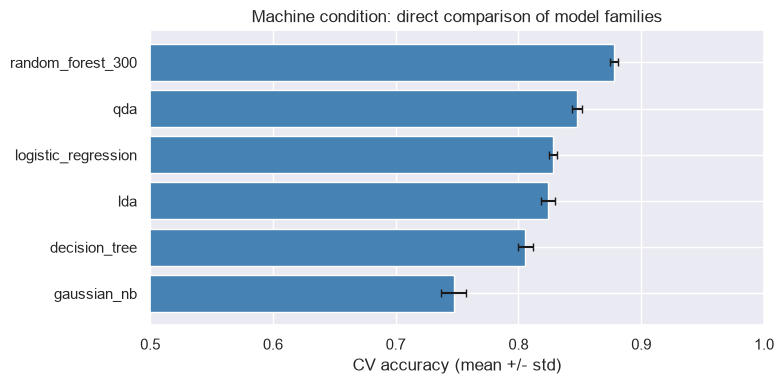

In [15]:
fig, axis = plt.subplots(figsize=(8, 4))
ordered = baseline_table.sort_values("mean")
axis.barh(ordered["model"], ordered["mean"], xerr=ordered["std"], capsize=3, color="steelblue")
axis.set_xlabel("CV accuracy (mean +/- std)")
axis.set_title("Machine condition: direct comparison of model families")
axis.set_xlim(0.5, 1.0)
save_figure(fig, "machine_model_comparison.png")
plt.show()

The random forest leads at 0.878, and QDA is the strongest of the three Gaussian models at 0.848.

Plain logistic regression (0.828) and LDA (0.824) are below QDA because their boundaries are linear, and Gaussian Naive Bayes is last at 0.747 because it assumes independent sensors while several pairs are correlated.

## 8. Hyper-parameter Tuning

### 8.1 Logistic Regression (linear): Regularization Strength

Logistic regression is fitted by maximum likelihood with an L2 penalty; the
strength is set through `C`, the inverse of the penalty, so small `C` means
strong shrinkage.

In [16]:
logistic_rows = []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    model = Pipeline([("prep", scaled), ("model", LogisticRegression(C=C, max_iter=5000, random_state=SEED))])
    row = cross_validate_model(f"logistic_regression_C{C}", model, note="C sweep")
    logistic_rows.append({"C": C, "mean": row["mean"], "std": row["std"]})

show_table(pd.DataFrame(logistic_rows).sort_values("mean", ascending=False))

        C     mean      std
3   10.00  0.82925  0.00298
4  100.00  0.82919  0.00270
2    1.00  0.82800  0.00323
1    0.10  0.82469  0.00239
0    0.01  0.81819  0.00384


Accuracy rises from 0.818 at C = 0.01 to 0.829 at C = 10 and stays flat at C = 100. Hence we can see that a weaker penalty coefficient is better.

### 8.2 Logistic Regression with a Quadratic Basis: Optimal Degree and C

In [17]:
def polynomial_logistic(preprocessor, degree=2, C=1.0):
    """Logistic regression on a polynomial basis expansion."""
    return Pipeline([
        ("prep", preprocessor),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", LogisticRegression(C=C, max_iter=5000, random_state=SEED)),
    ])


quadratic_rows = []
for degree in [1, 2]:
    for C in [0.01, 0.1, 1.0, 10.0]:
        row = cross_validate_model(f"logistic_quadratic_degree{degree}_C{C}",
                                   polynomial_logistic(scaled, degree=degree, C=C),
                                   note="quadratic basis sweep")
        quadratic_rows.append({"degree": degree, "C": C, "mean": row["mean"], "std": row["std"]})

quadratic_table = pd.DataFrame(quadratic_rows).sort_values("mean", ascending=False).reset_index(drop=True)
show_table(quadratic_table)

   degree      C     mean      std
0       2   1.00  0.88538  0.00402
1       2  10.00  0.88469  0.00325
2       2   0.10  0.88444  0.00344
3       2   0.01  0.88144  0.00104
4       1  10.00  0.82925  0.00298
5       1   1.00  0.82800  0.00323
6       1   0.10  0.82469  0.00239
7       1   0.01  0.81819  0.00384


Degree 2 with C = 1 reaches 0.8853, clearly above the linear version (0.829).

### 8.3 QDA: Covariance Regularization

QDA estimates one covariance matrix per class. Adding a small regularisation to each covariance makes them invertible when features are strongly related.

In [18]:
try:
    broken = Pipeline([("prep", scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.0))]).fit(X_train, y_train)
except Exception as error:
    print("QDA without regularisation fails as expected:")
    print(type(error).__name__, "-", str(error)[:110])

qda_rows = []
for reg_param in [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]:
    row = cross_validate_model(f"qda_engineered_reg{reg_param}",
                               Pipeline([("prep", scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=reg_param))]),
                               note="regularisation sweep on engineered features")
    qda_rows.append({"features": "engineered", "reg_param": reg_param, "mean": row["mean"], "std": row["std"]})

for reg_param in [0.05, 0.1, 0.2]:
    row = cross_validate_model(f"qda_raw_reg{reg_param}",
                               Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=reg_param))]),
                               note="regularisation sweep on raw sensors")
    qda_rows.append({"features": "raw", "reg_param": reg_param, "mean": row["mean"], "std": row["std"]})

show_table(pd.DataFrame(qda_rows).sort_values("mean", ascending=False))

QDA without regularisation fails as expected:
LinAlgError - The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearit


     features  reg_param     mean      std
7         raw      0.100  0.84763  0.00372
6         raw      0.050  0.84625  0.00350
8         raw      0.200  0.84388  0.00326
4  engineered      0.200  0.83931  0.00465
3  engineered      0.100  0.83856  0.00418
2  engineered      0.050  0.83575  0.00266
1  engineered      0.010  0.82194  0.00311
5  engineered      0.500  0.82000  0.00679
0  engineered      0.001  0.80463  0.00440


Without regularisation the code crashes because `temp_difference` makes the class covariance singular.

With regularisation the best QDA on the engineered features reaches only 0.839, below the 0.848 obtained from the raw sensors at `reg_param = 0.1`.

Hence we continue using the raw-sensor version for QDA.

### 8.4 Gaussian Naive Bayes: Variance Smoothing

The variance of each feature within each class is estimated from the class sample.

A small smoothing value is added to every variance to avoid over-confident probabilities when a variance is estimated as very small.

In [19]:
nb_rows = []
for smoothing in [1e-9, 1e-6, 1e-3, 1e-1]:
    row = cross_validate_model(f"gaussian_nb_smoothing{smoothing}",
                               Pipeline([("prep", scaled), ("model", GaussianNB(var_smoothing=smoothing))]),
                               note="variance smoothing")
    nb_rows.append({"var_smoothing": smoothing, "mean": row["mean"], "std": row["std"]})
show_table(pd.DataFrame(nb_rows).sort_values("mean", ascending=False))

   var_smoothing     mean      std
3   1.000000e-01  0.75350  0.00852
2   1.000000e-03  0.74738  0.01025
1   1.000000e-06  0.74719  0.01016
0   1.000000e-09  0.74719  0.01016


The best setting (0.1) increases the score from 0.747 to 0.754.

### 8.5 Decision Tree

#### 8.5.1 Pre-pruning: Depth, Leaf Size, Split Size, Maximum Leaves

An unrestricted classification tree grows until the leaves have single values (maximally pure).

We tune four early stopping criteria: maximum depth, minimum leaf size, minimum samples needed to split a node, and the maximum number of leaves.

In [20]:
tree_rows = []
for depth in [8, 12, 16, None]:
    for leaf in [1, 5, 20]:
        for split in [2, 10]:
            for max_leaves in [None, 50]:
                row = cross_validate_model(
                    f"decision_tree_d{depth}_l{leaf}_s{split}_ml{max_leaves}",
                    Pipeline([("prep", plain), ("model", DecisionTreeClassifier(
                        max_depth=depth, min_samples_leaf=leaf,
                        min_samples_split=split, max_leaf_nodes=max_leaves,
                        random_state=SEED))]),
                    note="pre-pruning grid")
                tree_rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                                  "min_samples_split": split, "max_leaf_nodes": max_leaves,
                                  "mean": row["mean"], "std": row["std"]})
tree_table = pd.DataFrame(tree_rows).sort_values("mean", ascending=False).reset_index(drop=True)
show_table(tree_table.head(5))

   max_depth  min_samples_leaf  min_samples_split  max_leaf_nodes     mean      std
0       12.0                 5                 10             NaN  0.83887  0.00656
1       12.0                 5                  2             NaN  0.83887  0.00656
2       16.0                20                  2             NaN  0.83750  0.00546
3       16.0                20                 10             NaN  0.83750  0.00546
4        NaN                20                  2             NaN  0.83744  0.00551


The best pre-pruned tree has depth 12 with a minimum leaf size of 5 and scores 0.8389.

The unconstrained tree (no depth limit, leaf size 1) falls to 0.806, and depth-4 trees underfit around 0.772.

#### 8.5.2 Post-pruning: Cost-complexity Pruning (lambda)

The tree is grown fully and then cut back, using the cost-complexity criterion:

```
R_lambda(T) = R(T) + lambda * |T|
```

where R(T) is the training error, |T| the number of leaves.

     lambda     mean      std
0  0.000298  0.84288  0.00762
1  0.000416  0.84263  0.00687
2  0.000214  0.84031  0.00700
3  0.000581  0.83813  0.00438
4  0.000811  0.83406  0.00552


best pruning lambda = 0.00029824: 161 leaves, depth 14


saved figures/machine_tree_pruning.png


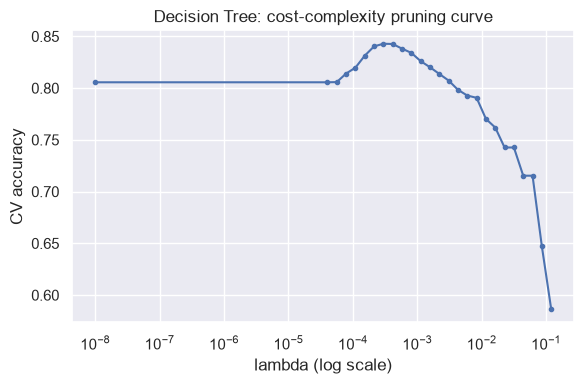

In [21]:
encoded = plain.fit_transform(X_train)
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(encoded, y_train)
positive_lambdas = path.ccp_alphas[path.ccp_alphas > 0]
lambda_candidates = [0.0] + [
    float(value) for value in np.round(np.geomspace(positive_lambdas.min(), positive_lambdas.max(), 25), 8)
]

ccp_rows = []
for lam in lambda_candidates:
    row = cross_validate_model(f"decision_tree_post_lambda{lam}",
                               Pipeline([("prep", plain), ("model", DecisionTreeClassifier(ccp_alpha=lam, random_state=SEED))]),
                               note="post-pruning sweep")
    ccp_rows.append({"lambda": lam, "mean": row["mean"], "std": row["std"]})

ccp_table = pd.DataFrame(ccp_rows).sort_values("mean", ascending=False).reset_index(drop=True)
show_table(ccp_table.head(5))

best_ccp_lambda = float(ccp_table.iloc[0]["lambda"])
ccp_tree = Pipeline([
    ("prep", plain),
    ("model", DecisionTreeClassifier(ccp_alpha=best_ccp_lambda, random_state=SEED)),
])
fitted_ccp = clone(ccp_tree).fit(X_train, y_train)
print(
    f"best pruning lambda = {best_ccp_lambda}: "
    f"{fitted_ccp.named_steps['model'].get_n_leaves()} leaves, "
    f"depth {fitted_ccp.named_steps['model'].get_depth()}"
)

ccp_curve = ccp_table.sort_values("lambda")
fig, axis = plt.subplots(figsize=(6, 4))
axis.plot(ccp_curve["lambda"].clip(lower=1e-8), ccp_curve["mean"], marker="o", markersize=3)
axis.set_xscale("log")
axis.set_xlabel("lambda (log scale)")
axis.set_ylabel("CV accuracy")
axis.set_title("Decision Tree: cost-complexity pruning curve")
save_figure(fig, "machine_tree_pruning.png")
plt.show()

Here post-pruning helps, where the best lambda (about 3e-4, keeping 161 leaves) increases the cross-validation (CV) accuracy of the tree from 0.8389 to 0.8429.

The curve rises steeply as lambda moves from 0 to that value (the unpruned tree at lambda = 0 scores only 0.806), then falls away as lambda becomes large enough to remove useful branches.

### 8.6 Random Forest

We tune the depths per tree, the minimum leaf size and the class weighting.

In [22]:
forest_rows = []
for depth in [None, 14, 20]:
    for leaf in [1, 4]:
        for class_weight in [None, "balanced"]:
            row = cross_validate_model(f"random_forest_d{depth}_l{leaf}_w{class_weight}",
                                       Pipeline([("prep", plain), ("model", RandomForestClassifier(
                                           n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                           class_weight=class_weight, random_state=SEED, n_jobs=-1))]),
                                       note="random forest grid")
            forest_rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                                "class_weight": class_weight, "mean": row["mean"], "std": row["std"]})
forest_table = pd.DataFrame(forest_rows).sort_values("mean", ascending=False).reset_index(drop=True)
show_table(forest_table.head(6))

   max_depth  min_samples_leaf class_weight     mean      std
0       14.0                 1          NaN  0.87888  0.00424
1        NaN                 1          NaN  0.87775  0.00351
2       20.0                 1          NaN  0.87725  0.00265
3        NaN                 4          NaN  0.87675  0.00471
4       14.0                 4          NaN  0.87631  0.00421
5       20.0                 4          NaN  0.87613  0.00453


The unweighted depth-14 random forest model is the best at 0.8787, but the differences inside the unweighted block are tiny (0.876 to 0.879).

## 9. Experiment: Class Imbalance Handling

We test out 3 scenarios with the two best-performing models so far (the quadratic logistic regression and QDA): reweighting the classes, random oversampling of the minority classes, and SMOTE, which creates synthetic minority samples by interpolating between neighbours.

In [23]:
for metric in ["accuracy", "f1_macro"]:
    rows = []
    for model_kind in ["logistic_quadratic", "qda"]:
        preprocessor = scaled if model_kind == "logistic_quadratic" else raw_scaled
        features = X_train if model_kind == "logistic_quadratic" else X_raw_train
        for variant in ["none", "reweight", "oversample", "smote"]:
            sampler = {"none": None, "reweight": None,
                       "oversample": RandomOverSampler(random_state=SEED),
                       "smote": SMOTE(random_state=SEED)}[variant]
            if model_kind == "logistic_quadratic":
                model = LogisticRegression(C=1.0, max_iter=5000, random_state=SEED,
                                           class_weight="balanced" if variant == "reweight" else None)
                steps = [("prep", preprocessor), ("poly", PolynomialFeatures(degree=2, include_bias=False))]
            else:
                model = QuadraticDiscriminantAnalysis(
                    reg_param=0.1, priors=[1 / 3, 1 / 3, 1 / 3] if variant == "reweight" else None)
                steps = [("prep", preprocessor)]
            if sampler is not None:
                steps.append(("sampler", sampler))
            steps.append(("model", model))
            scores = cross_validate(clone(ImbalancedPipeline(steps)), features, y_train,
                                    cv=make_folds(5, 1), scoring=SCORING[metric],
                                    n_jobs=1, error_score="raise")
            values = np.asarray(scores["test_score"], dtype=float)
            rows.append({"model": model_kind, "variant": variant,
                         "mean": round(float(values.mean()), 5), "std": round(float(values.std()), 5)})
    table = pd.DataFrame(rows).sort_values("mean", ascending=False)
    print(f"\n== {metric} ==")
    show_table(table)


== accuracy ==
                model     variant     mean      std
0  logistic_quadratic        none  0.88538  0.00402
1  logistic_quadratic    reweight  0.87400  0.00391
3  logistic_quadratic       smote  0.87369  0.00444
2  logistic_quadratic  oversample  0.87281  0.00352
4                 qda        none  0.84763  0.00372
6                 qda  oversample  0.84137  0.00307
5                 qda    reweight  0.83963  0.00409
7                 qda       smote  0.83769  0.00383



== f1_macro ==
                model     variant     mean      std
0  logistic_quadratic        none  0.87566  0.00432
1  logistic_quadratic    reweight  0.86632  0.00398
3  logistic_quadratic       smote  0.86625  0.00457
2  logistic_quadratic  oversample  0.86489  0.00405
4                 qda        none  0.82989  0.00376
6                 qda  oversample  0.82785  0.00320
5                 qda    reweight  0.82594  0.00390
7                 qda       smote  0.82520  0.00390


Each of these experiment scenarios lowered both metrics.

## 10. Model Diagnostics

We compare the three best models: the quadratic logistic regression and the random forest, plus QDA as the best of the Gaussian models, with metrics from the cross-validation results.

Note: the vote_quad_cubic_6040 model is discussed later in the notebook (which we will later see to be the best performing model)

In [ ]:
diagnostic_models = {
    "vote_quad_cubic_6040": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
    ], voting="soft", weights=[0.6, 0.4]),
    "logistic_quadratic": polynomial_logistic(scaled, degree=2, C=1.0),
    "qda_raw": Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))]),
}

oof_predictions, oof_probabilities = {}, {}
for name, model in diagnostic_models.items():
    features = X_raw_train if name == "qda_raw" else X_train
    probabilities = cross_val_predict(clone(model), features, y_train, cv=make_folds(5, 1),
                                      method="predict_proba", n_jobs=-1)
    oof_probabilities[name] = probabilities
    # For these classifiers the predicted label is the class with the highest
    # probability, so the labels come from the same pass.
    oof_predictions[name] = probabilities.argmax(axis=1)

### 10.1 Confusion Matrices

saved figures/machine_confusion_matrices.png


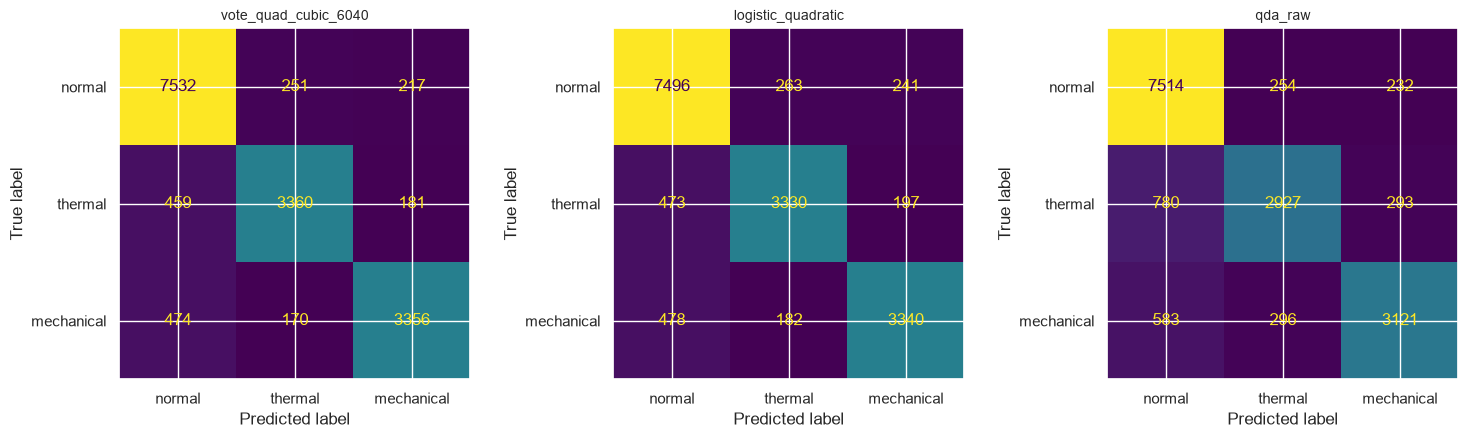

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, name in zip(axes, diagnostic_models):
    matrix = confusion_matrix(y_train, oof_predictions[name])
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=axis, colorbar=False, values_format="d")
    axis.set_title(name, fontsize=10)
save_figure(fig, "machine_confusion_matrices.png")
plt.show()

With all the models, normal machines are recognised best (7,498 of 8,000 for the quadratic logistic). The two failure classes each have between 660 and 670 misclassifications, and most of those misses fall into the normal class, roughly 470 to 480 per class.

Only about 180 to 200 machines, upon classification get swapped between thermal and mechanical, and those two classes are the ones whose sensor boxes overlap the most.

### 10.2 Per-class Metrics

In [26]:
report_table = pd.DataFrame(
    classification_report(y_train, oof_predictions["logistic_quadratic"],
                          target_names=CLASS_NAMES, output_dict=True)
).T.round(4)
show_table(report_table)

              precision  recall  f1-score     support
normal           0.8874  0.9370    0.9115   8000.0000
thermal          0.8821  0.8325    0.8566   4000.0000
mechanical       0.8841  0.8350    0.8588   4000.0000
accuracy         0.8854  0.8854    0.8854      0.8854
macro avg        0.8845  0.8682    0.8757  16000.0000
weighted avg     0.8853  0.8854    0.8846  16000.0000


The quadratic logistic regression reaches recall 93.7% on normal, 83.3% on thermal and 83.5% on mechanical, with precision and F1 following closely.

### 10.3 ROC Curves

saved figures/machine_roc_curves.png


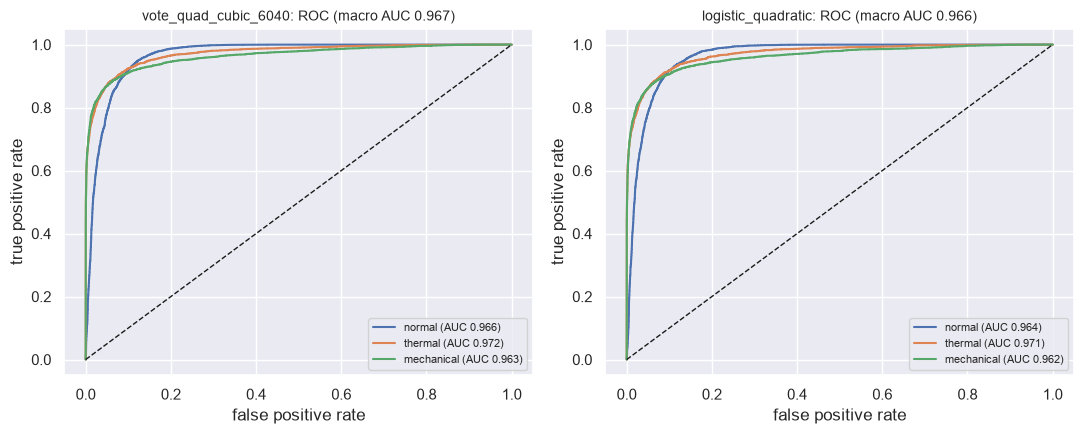

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, name in zip(axes, ["vote_quad_cubic_6040", "logistic_quadratic"]):
    probability = oof_probabilities[name]
    for index, class_name in enumerate(CLASS_NAMES):
        binary = (y_train == index).astype(int)
        fpr, tpr, _ = roc_curve(binary, probability[:, index])
        auc = roc_auc_score(binary, probability[:, index])
        axis.plot(fpr, tpr, label=f"{class_name} (AUC {auc:.3f})")
    axis.plot([0, 1], [0, 1], "k--", linewidth=1)
    axis.set_xlabel("false positive rate")
    axis.set_ylabel("true positive rate")
    overall = roc_auc_score(y_train, probability, multi_class="ovr")
    axis.set_title(f"{name}: ROC (macro AUC {overall:.3f})", fontsize=10)
    axis.legend(fontsize=8)
save_figure(fig, "machine_roc_curves.png")
plt.show()

### 10.4 Balanced Metrics and the Imbalance Question

                  model  accuracy  balanced_accuracy  f1_macro
0  vote_quad_cubic_6040    0.8905             0.8735    0.8814
1    logistic_quadratic    0.8854             0.8682    0.8757
2               qda_raw    0.8476             0.8171    0.8299


saved figures/machine_balanced_metrics.png


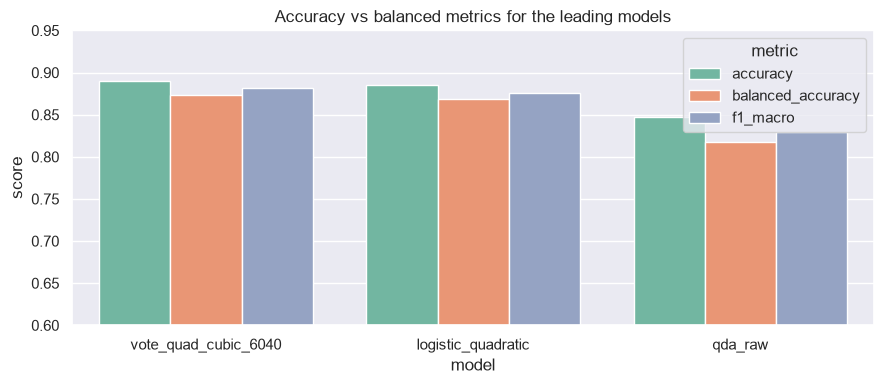

In [28]:
balanced_rows = []
for name, prediction in oof_predictions.items():
    balanced_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_train, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_train, prediction),
        "f1_macro": f1_score(y_train, prediction, average="macro"),
    })
balanced_table = pd.DataFrame(balanced_rows).round(4)
show_table(balanced_table)

melted = balanced_table.melt(id_vars="model", var_name="metric", value_name="score")
fig, axis = plt.subplots(figsize=(9, 4))
sns.barplot(data=melted, x="model", y="score", hue="metric", palette="Set2")
axis.set_ylim(0.6, 0.95)
axis.set_title("Accuracy vs balanced metrics for the leading models")
save_figure(fig, "machine_balanced_metrics.png")
plt.show()

### 10.5 Data Visualisation (t-SNE)

saved figures/machine_tsne_before_after.png


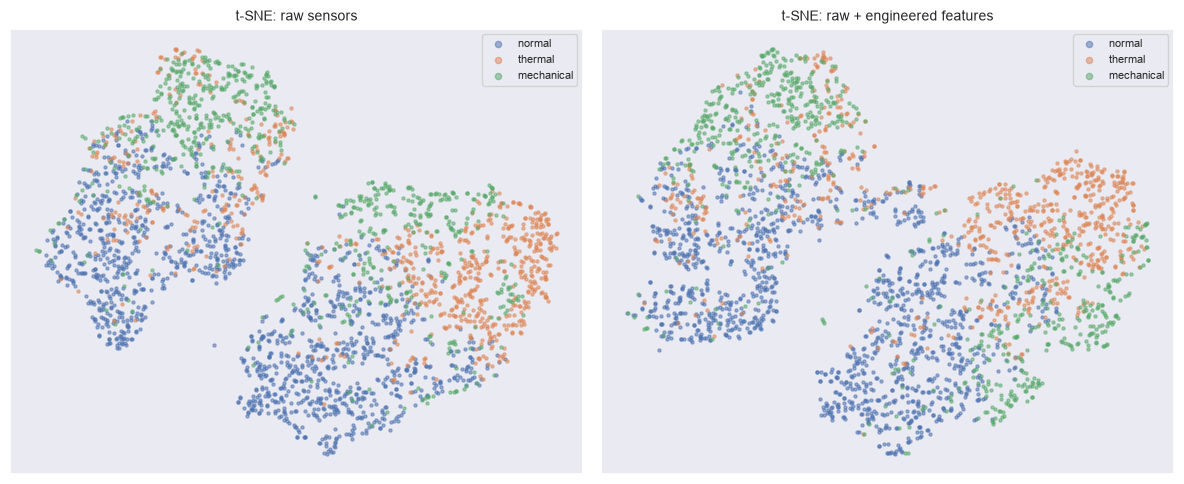

In [29]:
sample_index = train.sample(n=3000, random_state=SEED).index
sample_y = train.loc[sample_index, "condition"].to_numpy()
raw_frame = X_raw_train.loc[sample_index, sensors]
engineered_frame = X_train.loc[sample_index].select_dtypes(include="number")

imputer, scaler = SimpleImputer(strategy="median"), StandardScaler()
raw_scaled_sample = scaler.fit_transform(imputer.fit_transform(raw_frame))
imputer, scaler = SimpleImputer(strategy="median"), StandardScaler()
engineered_scaled_sample = scaler.fit_transform(imputer.fit_transform(engineered_frame))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, matrix, title in (
    (axes[0], raw_scaled_sample, "raw sensors"),
    (axes[1], engineered_scaled_sample, "raw + engineered features"),
):
    embedding = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca").fit_transform(matrix)
    for index, class_name in enumerate(CLASS_NAMES):
        axis.scatter(embedding[sample_y == index, 0], embedding[sample_y == index, 1],
                     s=5, alpha=0.5, label=class_name)
    axis.set_title(f"t-SNE: {title}", fontsize=10)
    axis.set_xticks([])
    axis.set_yticks([])
    axis.legend(fontsize=8, markerscale=2)
save_figure(fig, "machine_tsne_before_after.png")
plt.show()

## 11. Cross-Validation of Shortlisted Models

The three leading models are re-evaluated with 5 folds repeated 3 times (15 validation scores each) to check that the ranking is not tied to one particular fold split.

In [30]:
for name, model in [("logistic_quadratic_5x3", polynomial_logistic(scaled, degree=2, C=1.0)),
                    ("random_forest_depth14_5x3", Pipeline([("prep", plain), ("model", RandomForestClassifier(
                        n_estimators=300, max_depth=14, random_state=SEED, n_jobs=-1))])),
                    ("qda_raw_5x3", Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))]))]:
    cross_validate_model(name, model, n_repeats=3, note="5 folds x 3 repeats")

show_table(pd.DataFrame([row for row in LOG if "5x3" in row["model"]])[["model", "mean", "std"]])

                       model     mean      std
0     logistic_quadratic_5x3  0.88535  0.00537
1  random_forest_depth14_5x3  0.87781  0.00519
2                qda_raw_5x3  0.84758  0.00682


## 12. Metrics Comparison

In [31]:
family_models = {
    "logistic_regression_C10": Pipeline([("prep", scaled), ("model", LogisticRegression(C=10.0, max_iter=5000, random_state=SEED))]),
    "lda": Pipeline([("prep", scaled), ("model", LinearDiscriminantAnalysis())]),
    "qda_raw_reg0.1": Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))]),
    "gaussian_nb_smoothing0.1": Pipeline([("prep", scaled), ("model", GaussianNB(var_smoothing=0.1))]),
    "decision_tree_prepruned": Pipeline([("prep", plain), ("model", DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=SEED))]),
    "decision_tree_postpruned": ccp_tree,
    "random_forest_depth14": Pipeline([("prep", plain), ("model", RandomForestClassifier(n_estimators=300, max_depth=14, random_state=SEED, n_jobs=-1))]),
    "logistic_quadratic_degree2_C1": polynomial_logistic(scaled, degree=2, C=1.0),
}

full_table = pd.DataFrame([cross_validate_metrics(name, model) for name, model in family_models.items()])
full_table = full_table.sort_values("accuracy", ascending=False).reset_index(drop=True)
show_table(full_table)

                           model  accuracy  balanced_accuracy  f1_macro
0  logistic_quadratic_degree2_C1    0.8854             0.8682    0.8757
1          random_forest_depth14    0.8789             0.8558    0.8659
2                 qda_raw_reg0.1    0.8476             0.8171    0.8299
3       decision_tree_postpruned    0.8429             0.8194    0.8259
4        decision_tree_prepruned    0.8389             0.8126    0.8206
5        logistic_regression_C10    0.8293             0.8037    0.8104
6                            lda    0.8239             0.7893    0.8022
7       gaussian_nb_smoothing0.1    0.7535             0.7244    0.7273


## 13. Submission CSV Creation

In [32]:
submission_models = {
    "logistic_regression_C10": Pipeline([("prep", scaled), ("model", LogisticRegression(C=10.0, max_iter=5000, random_state=SEED))]),
    "logistic_quadratic_C1": polynomial_logistic(scaled, degree=2, C=1.0),
    "lda": Pipeline([("prep", scaled), ("model", LinearDiscriminantAnalysis())]),
    "qda_raw_reg0.1": Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))]),
    "gaussian_nb": Pipeline([("prep", scaled), ("model", GaussianNB())]),
    "decision_tree_depth12_leaf5": Pipeline([("prep", plain), ("model", DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=SEED))]),
    "decision_tree_postpruned": ccp_tree,
    "random_forest_depth14": Pipeline([("prep", plain), ("model", RandomForestClassifier(n_estimators=300, max_depth=14, random_state=SEED, n_jobs=-1))]),
    "vote_quad_cubic_5050": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
    ], voting="soft", weights=[0.5, 0.5]),
    "vote_quad_cubic_6040": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
    ], voting="soft", weights=[0.6, 0.4]),
    "vote_quad_cubic_rf_442": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
        ("forest", Pipeline([("prep", plain), ("model", RandomForestClassifier(
            n_estimators=500, max_depth=18, max_features=0.3, min_samples_leaf=2,
            random_state=SEED, n_jobs=-1))])),
    ], voting="soft", weights=[0.4, 0.4, 0.2]),
    "ensemble_forest_qda": VotingClassifier([
        ("forest", Pipeline([("prep", plain), ("model", RandomForestClassifier(n_estimators=300, max_depth=14, random_state=SEED, n_jobs=-1))])),
        ("qda", Pipeline([("prep", raw_scaled), ("model", QuadraticDiscriminantAnalysis(reg_param=0.1))])),
    ], voting="soft"),
}

written = []
for name, model in submission_models.items():
    uses_raw = name == "qda_raw_reg0.1"
    path = fit_and_write_submission(name, model, X_features=X_raw_train if uses_raw else None)
    written.append({"model": name, "file": path.name})
show_table(pd.DataFrame(written))

best_frame = pd.read_csv(SUBMISSIONS / "submission_vote_quad_cubic_6040.csv")
best_frame.to_csv(SUBMISSIONS / "submission.csv", index=False)
print("upload-ready file: submissions/machine_condition/submission.csv")
show_table(best_frame.head())

                          model                                        file
0       logistic_regression_C10      submission_logistic_regression_C10.csv
1         logistic_quadratic_C1        submission_logistic_quadratic_C1.csv
2                           lda                          submission_lda.csv
3                qda_raw_reg0.1               submission_qda_raw_reg0.1.csv
4                   gaussian_nb                  submission_gaussian_nb.csv
5   decision_tree_depth12_leaf5  submission_decision_tree_depth12_leaf5.csv
6      decision_tree_postpruned     submission_decision_tree_postpruned.csv
7         random_forest_depth14        submission_random_forest_depth14.csv
8          vote_quad_cubic_5050         submission_vote_quad_cubic_5050.csv
9          vote_quad_cubic_6040         submission_vote_quad_cubic_6040.csv
10       vote_quad_cubic_rf_442       submission_vote_quad_cubic_rf_442.csv
11          ensemble_forest_qda          submission_ensemble_forest_qda.csv
upload-ready

## 14. Experiment: Combining / blending the top models

The two strongest single models are the quadratic and cubic logistic regressions, so here we also test three soft-voting combinations of the pair (considering a combination with random forest in the third variant):
 - An even 50/50 vote
 - A 60/40 vote weighted toward the quadratic model, and,
 - A 40/40/20 vote with Random Forest.
 
Each combination is scored with the same 5-fold cross-validation as we have been using above.

In [33]:
vote_candidates = {
    "vote_quad_cubic_5050": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
    ], voting="soft", weights=[0.5, 0.5]),
    "vote_quad_cubic_6040": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
    ], voting="soft", weights=[0.6, 0.4]),
    "vote_quad_cubic_rf_442": VotingClassifier([
        ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
        ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
        ("forest", Pipeline([("prep", plain), ("model", RandomForestClassifier(
            n_estimators=500, max_depth=18, max_features=0.3, min_samples_leaf=2,
            random_state=SEED, n_jobs=-1))])),
    ], voting="soft", weights=[0.4, 0.4, 0.2]),
}

vote_table = pd.DataFrame([cross_validate_metrics(name, model) for name, model in vote_candidates.items()])
vote_table = vote_table.sort_values("accuracy", ascending=False).reset_index(drop=True)
show_table(vote_table)

                    model  accuracy  balanced_accuracy  f1_macro
0  vote_quad_cubic_rf_442    0.8919             0.8746    0.8828
1    vote_quad_cubic_5050    0.8909             0.8738    0.8819
2    vote_quad_cubic_6040    0.8901             0.8730    0.8810


## 15. An 80/20 test of the best model

We also test the final model on an 80/20 split of the training data, to see how it behaves on rows it has never seen and how much it still depends on the amount of training data.

In [34]:
from sklearn.model_selection import train_test_split

X_fit, X_hold, y_fit, y_hold = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
small = X_fit.sample(frac=0.2, random_state=SEED)
X_small, y_small = small, y_fit.loc[small.index]
print("fit rows:", len(X_fit), "| 20% subset rows:", len(X_small), "| 20% test rows:", len(X_hold))

vote_best = VotingClassifier([
    ("quad", polynomial_logistic(scaled, degree=2, C=1.0)),
    ("cubic", polynomial_logistic(scaled, degree=3, C=0.3)),
], voting="soft", weights=[0.6, 0.4])
quadratic_final = polynomial_logistic(scaled, degree=2, C=1.0)

test_rows = []
for label, model, features_fit, target_fit in [
    ("vote 60/40 (80% train)", vote_best, X_fit, y_fit),
    ("vote 60/40 (20% train)", vote_best, X_small, y_small),
    ("quadratic logistic (80% train)", quadratic_final, X_fit, y_fit),
    ("quadratic logistic (20% train)", quadratic_final, X_small, y_small),
]:
    fitted = clone(model).fit(features_fit, target_fit)
    predictions = fitted.predict(X_hold)
    test_rows.append({
        "setting": label,
        "accuracy": round(float(accuracy_score(y_hold, predictions)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_hold, predictions)), 4),
        "f1_macro": round(float(f1_score(y_hold, predictions, average="macro")), 4),
    })

show_table(pd.DataFrame(test_rows))

fit rows: 12800 | 20% subset rows: 2560 | 20% test rows: 3200


                          setting  accuracy  balanced_accuracy  f1_macro
0          vote 60/40 (80% train)    0.9003             0.8854    0.8921
1          vote 60/40 (20% train)    0.8928             0.8763    0.8834
2  quadratic logistic (80% train)    0.8953             0.8798    0.8862
3  quadratic logistic (20% train)    0.8872             0.8731    0.8782


saved figures/machine_80_20_confusion.png


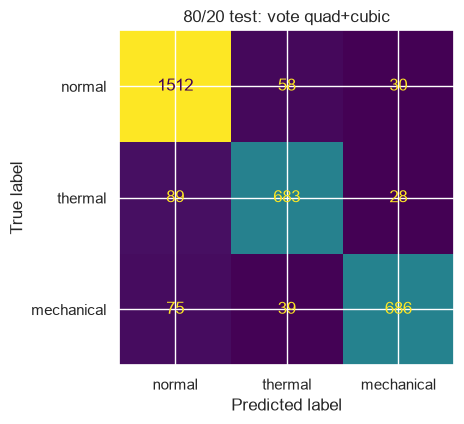

In [35]:
fitted = clone(vote_best).fit(X_fit, y_fit)
predictions = fitted.predict(X_hold)

matrix = confusion_matrix(y_hold, predictions)
display = ConfusionMatrixDisplay(matrix, display_labels=["normal", "thermal", "mechanical"])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
display.plot(ax=ax, colorbar=False, cmap="viridis")
ax.set_title("80/20 test: vote quad+cubic")
fig.tight_layout()
fig.savefig(FIGURES / "machine_80_20_confusion.png", dpi=150)
print("saved figures/machine_80_20_confusion.png")
plt.show()

## 16. Conclusion

* Even though the failure types are unevenly distributed (a 2:1:1 split), our accuracy metric isn't masking poor performance on a minority class. The lowest recall we saw was 83.3% for thermal failures, and our top model also led on standard accuracy, balanced accuracy, and macro F1 score.
* The raw sensor data separates the failure types in the same way that they should logically and physically. Adding our custom engineered features made the boundaries between the failure definite.
* As we saw, the decision boundaries between the machine states are curved. Upgrading standard Logistic Regression with degree-2 polynomial features increased the accuracy from 0.829 to 0.885, performing better than both QDA (0.848) and the Random Forest (0.879). A cubic basis with stronger regularisation reached slightly further still (0.889).
* When tuning the decision trees, we tested both pruning methods. Setting limits beforehand (max depth 12, minimum leaf size 5) gave us a maximum of 0.839 accuracy, while cost-complexity pruning helped increase that further to 0.842.
* We tried handling the class imbalance with class reweighting, oversampling, and SMOTE, but all of them ended up being detrimental to performance metrics.
* Finally, we observed that the model which performed the best was the 60/40 combination (with soft voting) of the quadratic and cubic logistic regressions, scoring 0.8901 accuracy in cross-validation. It scored 0.89125 on the public leaderboard for the industrial machine condition classification competition on Kaggle.